# Step 5. Models 2 to 4: random forests tested on unseen sites (Q2, Q3)

Random forests are trained and tested in exactly the same way. The only difference is the predictors, so any difference in score comes from the microbial data.

* **Model 2:** random forest with the 16 environmental variables.
* **Model 3:** random forest with the 16 environmental variables and the two share columns (`methanogen_share_pct`, `methanotroph_share_pct`).
* **Model 4 (optional):** random forest with the 16 environmental variables and all genera (CLR).

**What comes out:** R² and RMSE of all models, with their spread, in one table together with Model 1 and the reference model; one comparison figure and one measured-versus-predicted figure.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

SEED = 42
N_FOLDS = 10

C_ENV = "#2a78d6"; C_MIC = "#eb6834"; C_GEN = "#1baf7a"; C_GREY = "#8c8b87"; C_INK = "#2b2b2b"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "legend.frameon": False,
})

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

## 2. Data

Same preparation as in Steps 2 and 4: target log10(CH4 + 100); the 2 stations without CH4 and the 5 low-depth stations are removed; genera as CLR (pseudocount 0.5, per station); missing environmental values are filled with the median of the training sites inside every round.

In [2]:
DATA_FILE = "MIEF-PEAT_CH4_dataset_v0.csv"
CANDIDATES = [Path("."), Path("data"), Path("/content/drive/MyDrive/IDS-GroupProject")]
DATA_DIR = next((d for d in CANDIDATES if (d / DATA_FILE).exists()), None)
assert DATA_DIR is not None, f"Put {DATA_FILE} in one of {CANDIDATES} or set DATA_DIR by hand"
df_raw = pd.read_csv(DATA_DIR / DATA_FILE)

ENV = ["pH", "von_post_grade", "organic_matter_frac", "soil_moisture_vwc",
       "P_mg_kg", "K_mg_kg", "Ca_mg_kg", "Mg_mg_kg", "nitrate_mg_kg", "ammonium_mg_kg",
       "total_N_pct", "total_C_pct", "CN_ratio", "water_table_cm",
       "soil_temp_10cm_C", "soil_temp_20cm_C"]
SHARE = ["methanogen_share_pct", "methanotroph_share_pct"]
GENUS = [c for c in df_raw.columns if c.startswith("genus_")]

log_cnts = np.log(df_raw[GENUS].astype(float) + 0.5)
clr = log_cnts.sub(log_cnts.mean(axis=1), axis=0)
CLR = ["clr_" + c[len("genus_"):] for c in GENUS]
clr.columns = CLR

df = pd.concat([df_raw, clr], axis=1)
df = df[df.CH4_ugC_m2_h.notna() & ~df.low_depth_flag].reset_index(drop=True)
df["y"] = np.log10(df.CH4_ugC_m2_h + 100)
y = df.y.to_numpy()
print(f"{len(df)} stations from {df.site.nunique()} sites")

189 stations from 75 sites


## 3. Cross-validation by site

The sites are split into 10 parts. In each round the models are trained on 9 parts and tested on the remaining part; every part is tested once. All stations of one site are always in the same part. The same rounds are used for every model (and are the same as in Step 4).

In [3]:
folds = list(GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(df)), groups=df.site))

assert all(set(df.site.iloc[tr]).isdisjoint(df.site.iloc[te]) for tr, te in folds)   # no site in train and test
sizes = [df.site.iloc[te].nunique() for _, te in folds]
print(f"{len(folds)} rounds; test sites per round: {min(sizes)}-{max(sizes)}; "
      f"test stations per round: {min(len(te) for _, te in folds)}-{max(len(te) for _, te in folds)}")

10 rounds; test sites per round: 7-8; test stations per round: 14-25


**What could be the options when there are few sites per land use?** Some land uses have very few sites (peat extraction 2, hay field 4). In a random split, one round can hold most or all of their sites, so the model has (almost) never seen that land use, and their scores rest on very few sites. Options:

1. **Stratified group folds** (`StratifiedGroupKFold` with `land_use`): sites stay together, but each land use is spread over the rounds as evenly as possible.
2. **Repeat the cross-validation with several random splits** and report the range of the scores.
3. **Leave-one-site-out** cross-validation: each site is tested alone, so the most sites are available for training.
4. **Merge rare land uses** into a broader group (e.g. drained and managed) for stratification.
5. **Report the error per land use with the number of sites**, and do not draw conclusions for land uses with only a few sites.

In [4]:
display(df.groupby("land_use").agg(sites=("site", "nunique"), stations=("station_id", "size")).sort_values("sites"))

,sites,stations
land_use,,
Peat extraction,2,3
Hay field,4,9
Arable,8,22
Forest,8,30
Bog,14,34
Pasture,16,38
Fen,25,53


## 4. Models

Model 1 and the reference model are the same as in Step 4; they are included here so that all models are in one table. All random forests use the same settings: 500 trees, `max_features` = 1/3 of the predictors, `min_samples_leaf` = 3, seed 42.

In [5]:
def rf():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestRegressor(n_estimators=500, max_features=1/3, min_samples_leaf=3,
                                               random_state=SEED, n_jobs=-1))

MODELS = {
    "Reference (mean)":            (["soil_moisture_vwc"], lambda: DummyRegressor(strategy="mean")),
    "Model 1 (soil moisture)":     (["soil_moisture_vwc"], lambda: make_pipeline(SimpleImputer(strategy="median"), LinearRegression())),
    "Model 2 (RF, env)":           (ENV, rf),
    "Model 3 (RF, env + shares)":  (ENV + SHARE, rf),
    "Model 4 (RF, env + genera)":  (ENV + CLR, rf),
}

## 5. Train and test in every round

The predictions for the test stations of every round are collected. R² and RMSE are computed over all of them, and the RMSE of each round shows the spread.

In [6]:
results = {}
for name, (cols, make_model) in MODELS.items():
    pred = np.full(len(y), np.nan)
    fold_rmse = []
    for tr, te in folds:
        m = make_model().fit(df.loc[tr, cols], y[tr])
        pred[te] = m.predict(df.loc[te, cols])
        fold_rmse.append(rmse(y[te], pred[te]))
    results[name] = {"pred": pred, "fold_rmse": np.array(fold_rmse)}

scores = pd.DataFrame({name: {"R2": r2_score(y, r["pred"]), "RMSE": rmse(y, r["pred"]),
                              "RMSE spread (SD across rounds)": r["fold_rmse"].std(ddof=1)}
                       for name, r in results.items()}).T
scores.index.name = "model"
scores.round(3).to_csv(RES_DIR / "step5_scores.csv")
display(scores.round(3))

per_round = pd.DataFrame({n: r["fold_rmse"] for n, r in results.items()}, index=[f"round {i+1}" for i in range(N_FOLDS)])
per_round.round(3).to_csv(RES_DIR / "step5_rmse_per_round.csv")
print("RMSE of each round:")
display(per_round.round(3).T)

pred_table = df[["station_id", "site", "land_use", "y"]].copy()
for n, r in results.items():
    pred_table[n] = r["pred"]
pred_table.to_csv(RES_DIR / "step5_predictions.csv", index=False)

,R2,RMSE,RMSE spread (SD across rounds)
model,,,
Reference (mean),-0.037,0.680,0.178
Model 1 (soil moisture),0.143,0.618,0.152
"Model 2 (RF, env)",0.326,0.549,0.106
"Model 3 (RF, env + shares)",0.392,0.521,0.118
"Model 4 (RF, env + genera)",0.468,0.487,0.114


RMSE of each round:


,round 1,round 2,round 3,round 4,round 5,round 6,round 7,round 8,round 9,round 10
Reference (mean),0.678,0.808,0.664,0.568,0.605,0.380,0.580,0.512,0.972,0.878
Model 1 (soil moisture),0.570,0.782,0.651,0.543,0.562,0.346,0.488,0.507,0.823,0.775
"Model 2 (RF, env)",0.558,0.662,0.668,0.530,0.492,0.337,0.470,0.434,0.634,0.582
"Model 3 (RF, env + shares)",0.569,0.652,0.593,0.488,0.496,0.325,0.489,0.289,0.604,0.563
"Model 4 (RF, env + genera)",0.537,0.602,0.422,0.410,0.506,0.382,0.398,0.290,0.608,0.628


## 6. Comparison figure

Each bar is the RMSE of one model (lower is better); the black lines show the spread across rounds.

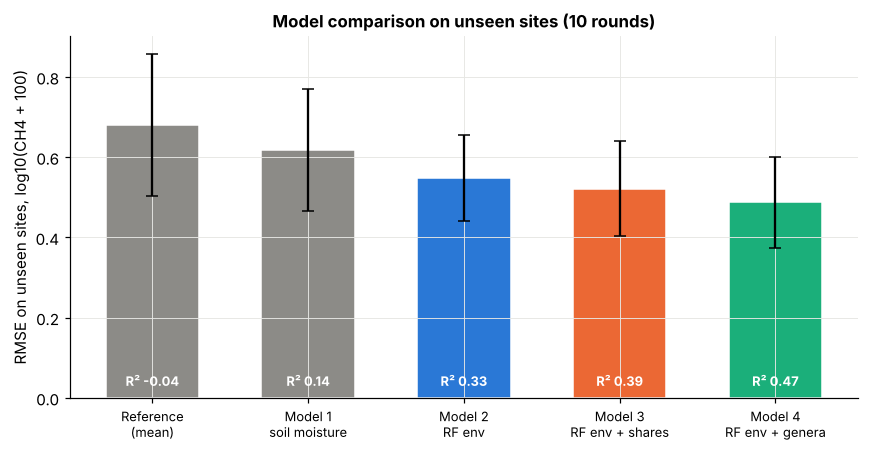

In [7]:
names = list(MODELS)
labels = ["Reference\n(mean)", "Model 1\nsoil moisture", "Model 2\nRF env", "Model 3\nRF env + shares", "Model 4\nRF env + genera"]
colors = [C_GREY, C_GREY, C_ENV, C_MIC, C_GEN]

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(names))
ax.bar(x, scores.loc[names, "RMSE"], yerr=scores.loc[names, "RMSE spread (SD across rounds)"],
       color=colors, capsize=4, width=0.6, edgecolor="white")
for i, n in enumerate(names):
    ax.text(i, 0.03, f"R² {scores.loc[n, 'R2']:.2f}", ha="center", color="white", fontsize=8.5, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylabel("RMSE on unseen sites, log10(CH4 + 100)")
ax.set_title("Model comparison on unseen sites (10 rounds)")
fig.tight_layout(); fig.savefig(FIG_DIR / "step5_model_comparison.png"); plt.show()

## 7. Measured vs predicted, Model 3

One dot per station. Every prediction comes from a model that did not see the station's site.

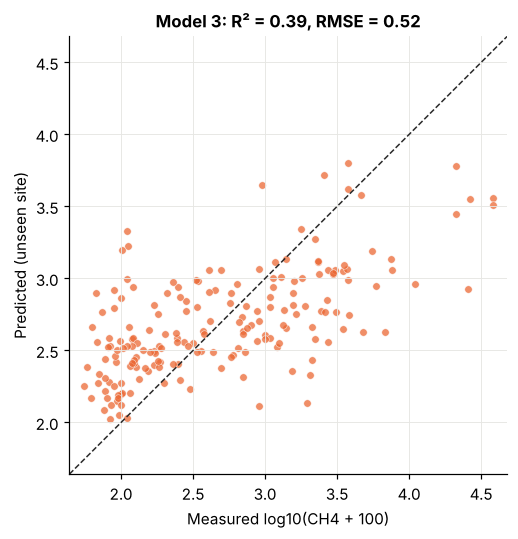

In [8]:
p3 = results["Model 3 (RF, env + shares)"]["pred"]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y, p3, s=24, color=C_MIC, alpha=0.75, edgecolor="white", linewidth=0.4)
lim = [min(y.min(), p3.min()) - 0.1, max(y.max(), p3.max()) + 0.1]
ax.plot(lim, lim, "--", color=C_INK, lw=1)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("Measured log10(CH4 + 100)"); ax.set_ylabel("Predicted (unseen site)")
ax.set_title(f"Model 3: R² = {scores.loc['Model 3 (RF, env + shares)', 'R2']:.2f}, "
             f"RMSE = {scores.loc['Model 3 (RF, env + shares)', 'RMSE']:.2f}")
fig.tight_layout(); fig.savefig(FIG_DIR / "step5_measured_vs_predicted_model3.png"); plt.show()

## 8. Additional checks

These go beyond the minimum of Step 5. They check whether the result depends on how the sites were split into rounds, and where the model makes its errors.

### 8.1 Repeat with 5 different splits of the sites

With only 75 sites, the scores can depend on which sites happen to be tested together. We repeat the cross-validation with 5 different random splits (seeds 42–46). The random forests also get the same seed.

In [9]:
def run(folds_, names, seed=SEED):
    out = {}
    for name in names:
        cols, make_model = MODELS[name]
        pred = np.full(len(y), np.nan)
        fr = []
        for tr, te in folds_:
            m = make_model()
            est = m[-1] if hasattr(m, "steps") else m
            if "random_state" in est.get_params():
                est.set_params(random_state=seed)
            m.fit(df.loc[tr, cols], y[tr])
            pred[te] = m.predict(df.loc[te, cols])
            fr.append(rmse(y[te], pred[te]))
        out[name] = {"R2": r2_score(y, pred), "RMSE": rmse(y, pred), "spread": np.std(fr, ddof=1)}
    return out

RF_NAMES = ["Model 2 (RF, env)", "Model 3 (RF, env + shares)", "Model 4 (RF, env + genera)"]
rows = []
for s in [42, 43, 44, 45, 46]:
    f_s = list(GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=s).split(np.zeros(len(df)), groups=df.site))
    for name, r in run(f_s, ["Reference (mean)", "Model 1 (soil moisture)"] + RF_NAMES, seed=s).items():
        rows.append({"seed": s, "model": name, "R2": r["R2"], "RMSE": r["RMSE"]})
seed_runs = pd.DataFrame(rows)
seed_runs.to_csv(RES_DIR / "step5_seed_runs.csv", index=False)

display(seed_runs.groupby("model", sort=False).agg(R2_mean=("R2", "mean"), R2_min=("R2", "min"), R2_max=("R2", "max"),
                                                   RMSE_mean=("RMSE", "mean"), RMSE_min=("RMSE", "min"), RMSE_max=("RMSE", "max")).round(3))
piv = seed_runs.pivot(index="seed", columns="model", values="RMSE")
for other in RF_NAMES[1:]:
    print(f"Splits where {other.split(' (')[0]} has lower RMSE than Model 2: "
          f"{int((piv[other] < piv['Model 2 (RF, env)']).sum())} of {len(piv)}")

,R2_mean,R2_min,R2_max,RMSE_mean,RMSE_min,RMSE_max
model,,,,,,
Reference (mean),-0.025,-0.037,-0.011,0.676,0.672,0.680
Model 1 (soil moisture),0.141,0.137,0.144,0.619,0.618,0.621
"Model 2 (RF, env)",0.315,0.296,0.339,0.553,0.543,0.561
"Model 3 (RF, env + shares)",0.389,0.372,0.402,0.522,0.517,0.530
"Model 4 (RF, env + genera)",0.457,0.426,0.472,0.492,0.485,0.506


Splits where Model 3 has lower RMSE than Model 2: 5 of 5
Splits where Model 4 has lower RMSE than Model 2: 5 of 5


### 8.2 Stratified rounds by land use

One of the options for few sites per land use: `StratifiedGroupKFold` keeps all stations of a site together, but spreads each land use over the rounds as evenly as possible.

In [10]:
folds_strat = list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
                   .split(np.zeros(len(df)), df.land_use, groups=df.site))
assert all(set(df.site.iloc[tr]).isdisjoint(df.site.iloc[te]) for tr, te in folds_strat)

def sites_per_round(fs):
    return pd.DataFrame([df.iloc[te].groupby("land_use").site.nunique() for _, te in fs],
                        index=[f"round {i+1}" for i in range(len(fs))]).fillna(0).astype(int).T
print("Test sites per land use in each round, normal rounds:")
display(sites_per_round(folds))
print("Test sites per land use in each round, stratified rounds:")
display(sites_per_round(folds_strat))

strat = run(folds_strat, list(MODELS))
display(pd.DataFrame({"R2 (normal)": scores["R2"], "R2 (stratified)": {n: r["R2"] for n, r in strat.items()},
                      "RMSE (normal)": scores["RMSE"], "RMSE (stratified)": {n: r["RMSE"] for n, r in strat.items()},
                      "spread (stratified)": {n: r["spread"] for n, r in strat.items()}}).round(3))

Test sites per land use in each round, normal rounds:


,round 1,round 2,round 3,round 4,round 5,round 6,round 7,round 8,round 9,round 10
land_use,,,,,,,,,,
Arable,2,0,2,0,0,1,0,0,1,2
Bog,2,1,3,1,0,3,1,0,2,1
Fen,1,5,1,5,3,0,3,3,2,2
Pasture,2,2,1,1,3,1,2,3,1,0
Peat extraction,1,0,0,0,0,0,0,0,1,0
Forest,0,0,1,1,2,1,1,1,0,1
Hay field,0,0,0,0,1,1,0,0,1,1


Test sites per land use in each round, stratified rounds:


,round 1,round 2,round 3,round 4,round 5,round 6,round 7,round 8,round 9,round 10
land_use,,,,,,,,,,
Bog,1,2,1,1,2,1,2,1,1,2
Fen,4,1,3,2,2,2,3,2,3,3
Forest,1,0,1,1,1,1,1,0,1,1
Pasture,2,2,1,2,1,2,2,1,2,1
Arable,0,1,1,1,1,0,1,1,1,1
Hay field,0,1,0,0,0,1,0,1,1,0
Peat extraction,0,0,0,0,1,1,0,0,0,0


,R2 (normal),R2 (stratified),RMSE (normal),RMSE (stratified),spread (stratified)
Reference (mean),-0.037,-0.025,0.680,0.676,0.107
Model 1 (soil moisture),0.143,0.143,0.618,0.618,0.087
"Model 2 (RF, env)",0.326,0.303,0.549,0.558,0.117
"Model 3 (RF, env + shares)",0.392,0.389,0.521,0.522,0.110
"Model 4 (RF, env + genera)",0.468,0.446,0.487,0.497,0.115


### 8.3 Where does Model 3 make its errors?

Error = predicted − measured (positive = the model predicts too much CH4).

In [11]:
err = df[["station_id", "site", "land_use", "y"]].rename(columns={"y": "measured"})
err["predicted"] = results["Model 3 (RF, env + shares)"]["pred"]
err["error"] = err.predicted - err.measured

print("Largest errors of Model 3:")
display(err.reindex(err.error.abs().sort_values(ascending=False).index).head(8).round(2))

per_lu = err.groupby("land_use").apply(lambda g: pd.Series({
    "sites": g.site.nunique(), "stations": len(g),
    "RMSE": rmse(g.measured, g.predicted), "mean error (bias)": g.error.mean()}))
per_lu[["sites", "stations"]] = per_lu[["sites", "stations"]].astype(int)
per_lu = per_lu.sort_values("sites", ascending=False)
per_lu.round(3).to_csv(RES_DIR / "step5_model3_error_per_land_use.csv")
print("Error of Model 3 per land use (few sites = uncertain):")
display(per_lu.round(3))

Largest errors of Model 3:


,station_id,site,land_use,measured,predicted,error
136,Y146B,Khabarovsk_fen,Fen,4.41,2.93,-1.48
122,Y133,Colombia_paramo,Bog,2.04,3.33,1.29
146,Y156,Myanmar_drained_fen_2,Pasture,3.83,2.63,-1.21
187,Y198,Morocco_bog_2,Bog,2.01,3.20,1.19
121,Y132,Morocco_bog_2,Bog,2.05,3.23,1.18
53,Y061,Uganda_drained_fen_2,Pasture,3.29,2.14,-1.16
149,Y159,Myanmar_fen,Fen,4.04,2.96,-1.08
168,Y178,Taiwan_recreation,Fen,4.58,3.51,-1.07


Error of Model 3 per land use (few sites = uncertain):


,sites,stations,RMSE,mean error (bias)
land_use,,,,
Fen,25,53,0.549,-0.112
Pasture,16,38,0.529,-0.140
Bog,14,34,0.599,0.151
Arable,8,22,0.465,-0.047
Forest,8,30,0.441,0.205
Hay field,4,9,0.444,0.229
Peat extraction,2,3,0.235,0.231


## 9. Summary

| | R² | RMSE | spread |
|---|---|---|---|
| Reference (mean) | −0.04 | 0.680 | 0.18 |
| Model 1 (soil moisture) | 0.14 | 0.618 | 0.15 |
| Model 2 (RF, env) | 0.33 | 0.549 | 0.11 |
| Model 3 (RF, env + shares) | 0.39 | 0.521 | 0.12 |
| Model 4 (RF, env + genera) | 0.47 | 0.487 | 0.11 |

* **Q2:** all three random forests beat the reference model and Model 1 on unseen sites. With the 16 environmental variables (Model 2) the forest explains about a third of the differences in CH4 between stations (R² = 0.33).
* **Q3:** adding the two microbial shares (Model 3) lowers the RMSE by 0.03 (0.549 → 0.521), and adding all genera (Model 4) by 0.06 (→ 0.487). Both differences are smaller than the spread of the RMSE across rounds (0.11–0.12), so by the rule of the guideline the microbial data **do not clearly improve** the prediction. The scores point in the direction of a small gain, which Step 7 will test.
* **Measured vs predicted:** the forest pulls predictions towards the middle: the highest emitters are under-predicted and many low emitters over-predicted.
* **Different splits of the sites (8.1):** with 5 random splits, Model 3 and Model 4 have a lower RMSE than Model 2 in 5 of 5 splits (Model 3: R² 0.37–0.40). The direction of the small gain is stable, even though it is smaller than the spread within one split.
* **Stratified rounds by land use (8.2):** almost the same scores (Model 2 R² 0.30, Model 3 0.39, Model 4 0.45), so the result does not depend on how the land uses fall into the rounds.
* **Errors (8.3):** the largest errors are single sites that behave differently from similar sites (e.g. Khabarovsk fen, Colombia páramo, Morocco bog 2). Per land use, the error is largest for bogs (RMSE 0.60); the model over-predicts bogs, forests and hay fields and under-predicts fens and pastures. Results for hay field (4 sites) and peat extraction (2 sites) rest on very few sites.